# Figure S4: QTL discovery by population

QTL discovery proportions across ancestry groups and molecular assays.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_PAPER_ROOT` to the local
paper directory and `QTL_SOURCE_ROOT` to the figure checkout with staged inputs
and saved objects. For example, set these variables in the R session before
you run the cells. Paths can contain spaces.

Run the cells from top to bottom. The preparation links show the filters, joins,
and counts used to produce the plot inputs. New PDFs and PNGs go to
`notebook_outputs/`. The plotting scripts are in `notebooks/current/`.


## Prepare the plotted data

The scripts below prepare filters, joins, counts, and summaries from source result tables. Their inputs and execution order are listed in `preparation/manifest.json`. The source data are not included in Git.

- [fig1_gene_reference](../../preparation/Fig1/00_gene_reference.R): Extract the GENCODE v48 gene records and stable IDs from the raw GTF.
- [fig1_population_discovery](../../preparation/Fig1/06_population_discovery.R): Recompute the historical S4 BH discovery proportions within each raw permutation-result file; count the shared reference-cohort samples.

Run `python3 tools/prepare_figure_data.py --list` from the repository root. Use the named root options described in `preparation/README.md`. Set `QTL_PREP_ROOT` to that run's output directory before running this notebook. The notebook then reads generated files from its `paper/` and `source/` folders. Other inputs and reference images still come from the original roots. A script with an unavailable source input is identified in the preparation manifest.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
prepared_root <- Sys.getenv("QTL_PREP_ROOT")
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  path <- file.path(root, relative)
  if (nzchar(prepared_root) && variable %in% c("QTL_PAPER_ROOT", "QTL_SOURCE_ROOT")) {
    namespace <- if (variable == "QTL_PAPER_ROOT") "paper" else "source"
    prepared_relative <- file.path(namespace, relative)
    generated <- file.path(prepared_root, prepared_relative)
    if (file.exists(generated)) {
      path <- generated
      variable <- "QTL_PREP_ROOT"
      relative <- prepared_relative
    }
  }
  if (!file.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  input_records[[paste(variable, relative, sep = ":")]] <- list(
    root = variable, path = relative, md5 = unname(tools::md5sum(path)))
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display reference Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Read the saved population summaries

Plot QTL discovery by ancestry group and assay. This notebook does not rerun QTL discovery. The sample sizes are common reference-cohort counts that the original source reused across assays.


In [2]:
s4 <- readr::read_tsv(paper_file("Supplemental Figures/01_Supplemental_drafts/Figure1_QTL_discovery_by_population/population_QTL_discovery_data.tsv"), show_col_types = FALSE)
stopifnot(nrow(s4) == 21L, all(dplyr::between(s4$proportion_significant, 0, 1)),
          !anyDuplicated(s4[c("assay", "population")]))
s4 <- s4 %>%
  mutate(assay = factor(assay, c("eQTL", "sQTL", "pQTL")),
         population = factor(population, c("Combined", "AFR", "AMR", "EAS", "EUR", "SAS", "MID")))


## Draw the saved discovery proportions

Each point is a population and assay summary. The x axis uses the saved reference sample count. It is not an assay-specific participant count. No confidence interval or fitted curve is added.


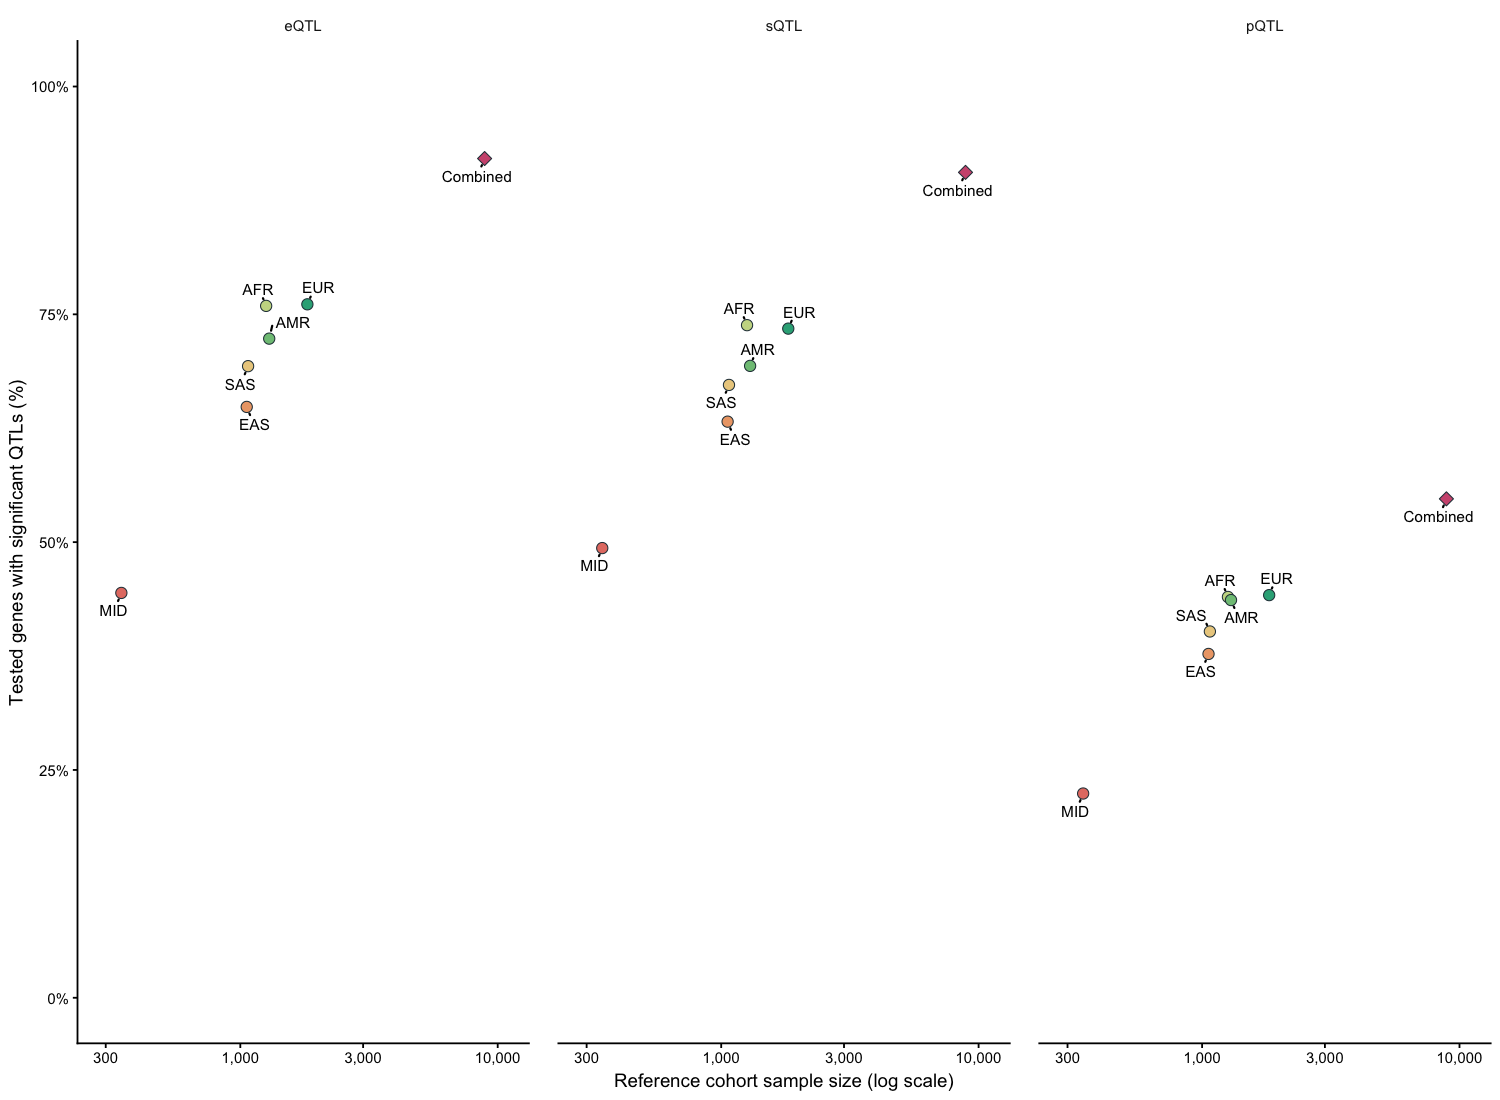

In [3]:
suppressPackageStartupMessages(library(ggrepel))
fills <- s4 %>% distinct(population, colour) %>% deframe()
shapes <- s4 %>% distinct(population, marker) %>% deframe()
figure <- ggplot(s4, aes(source_reference_sample_n, proportion_significant)) +
  geom_point(aes(fill = population, shape = population), size = 2.3, colour = "#263B45", stroke = 0.35) +
  geom_text_repel(aes(label = population), seed = 71, size = 2.6,
                  min.segment.length = 0, box.padding = 0.3,
                  point.padding = 0.2, max.overlaps = Inf) +
  facet_grid(~assay) +
  scale_fill_manual(values = fills) +
  scale_shape_manual(values = shapes) +
  scale_x_log10(limits = c(280, 11000), breaks = c(300, 1000, 3000, 10000), labels = scales::label_comma()) +
  scale_y_continuous(limits = c(0, 1), labels = scales::label_percent(), breaks = seq(0, 1, 0.25)) +
  labs(x = "Reference cohort sample size (log scale)", y = "Tested genes with significant QTLs (%)") +
  theme_classic(base_size = 9) +
  theme(strip.background = element_blank(), legend.position = "none",
        panel.spacing.x = grid::unit(5, "mm"))
print(figure)


## Save aggregate outputs

Save the figure and the 21 study summaries. No participant records are read or written. The source field source_n_tested counts tested rows, not significant genes.


In [4]:
save_plot(figure, "supplements/S4", 184, 85)
readr::write_tsv(s4 %>% select(assay, population, proportion_significant, source_n_tested,
                              significant_count_from_saved_summary, source_reference_sample_n),
                 output_file("supplements/S4_summary.tsv"))


Export aggregate plot: supplements/S4
